In the past Notebooks we have:
- Imported the data 
- chose the most important features
- chose the the model with most accuracy
- It's time to predict the response.

G1 G2 and G3 are final grades, G3 is where a student pass / fail, we will have to convert G3 to a binary response. 


In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split ,cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import RocCurveDisplay, auc, roc_curve , roc_auc_score
from sklearn.datasets import make_classification

In [2]:
%store -r df
df


,school,age,Medu,reason,traveltime,studytime,failures,nursery,higher,internet,famrel,freetime,Dalc,Walc,health,absences,G1,G2,G3
0,GP,18,4,course,2,2,0,yes,yes,no,4,3,1,1,3,4,0,11,11
1,GP,17,1,course,1,2,0,no,yes,yes,5,3,1,1,3,2,9,11,11
2,GP,15,1,other,1,2,0,yes,yes,yes,4,3,2,3,3,6,12,13,12
3,GP,15,4,home,1,3,0,yes,yes,yes,3,2,1,1,5,0,14,14,14
4,GP,16,3,home,1,2,0,yes,yes,no,4,3,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,19,2,course,1,3,1,no,yes,yes,5,4,1,2,5,4,10,11,10
645,MS,18,3,course,1,2,0,yes,yes,yes,4,3,1,1,1,4,15,15,16
646,MS,18,1,course,2,2,0,yes,yes,no,1,1,1,1,5,6,11,12,9
647,MS,17,3,course,2,1,0,no,yes,yes,2,4,3,4,2,6,10,10,10


In [3]:
df['pass_fail'] = (df['G3'] >= 10).astype(int)
df

,school,age,Medu,reason,traveltime,studytime,failures,nursery,higher,internet,famrel,freetime,Dalc,Walc,health,absences,G1,G2,G3,pass_fail
0,GP,18,4,course,2,2,0,yes,yes,no,4,3,1,1,3,4,0,11,11,1
1,GP,17,1,course,1,2,0,no,yes,yes,5,3,1,1,3,2,9,11,11,1
2,GP,15,1,other,1,2,0,yes,yes,yes,4,3,2,3,3,6,12,13,12,1
3,GP,15,4,home,1,3,0,yes,yes,yes,3,2,1,1,5,0,14,14,14,1
4,GP,16,3,home,1,2,0,yes,yes,no,4,3,1,2,5,0,11,13,13,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,19,2,course,1,3,1,no,yes,yes,5,4,1,2,5,4,10,11,10,1
645,MS,18,3,course,1,2,0,yes,yes,yes,4,3,1,1,1,4,15,15,16,1
646,MS,18,1,course,2,2,0,yes,yes,no,1,1,1,1,5,6,11,12,9,0
647,MS,17,3,course,2,1,0,no,yes,yes,2,4,3,4,2,6,10,10,10,1


In [4]:
X = df.drop(columns=["G3","G2", "G1","pass_fail"])
y = df["pass_fail"]


In [5]:
X_encoded = pd.get_dummies(X, columns=['school', 'reason', 'nursery', 'higher', 'internet'])
X_encoded.head()

,age,Medu,traveltime,studytime,failures,famrel,freetime,Dalc,Walc,health,...,reason_course,reason_home,reason_other,reason_reputation,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes
0,18,4,2,2,0,4,3,1,1,3,...,True,False,False,False,False,True,False,True,True,False
1,17,1,1,2,0,5,3,1,1,3,...,True,False,False,False,True,False,False,True,False,True
2,15,1,1,2,0,4,3,2,3,3,...,False,False,True,False,False,True,False,True,False,True
3,15,4,1,3,0,3,2,1,1,5,...,False,True,False,False,False,True,False,True,False,True
4,16,3,1,2,0,4,3,1,2,5,...,False,True,False,False,False,True,False,True,True,False


### Decision Tree Classifier

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded,y,random_state = 0)

clf = DecisionTreeClassifier(random_state = 0)
clf = clf.fit(X_train, y_train)

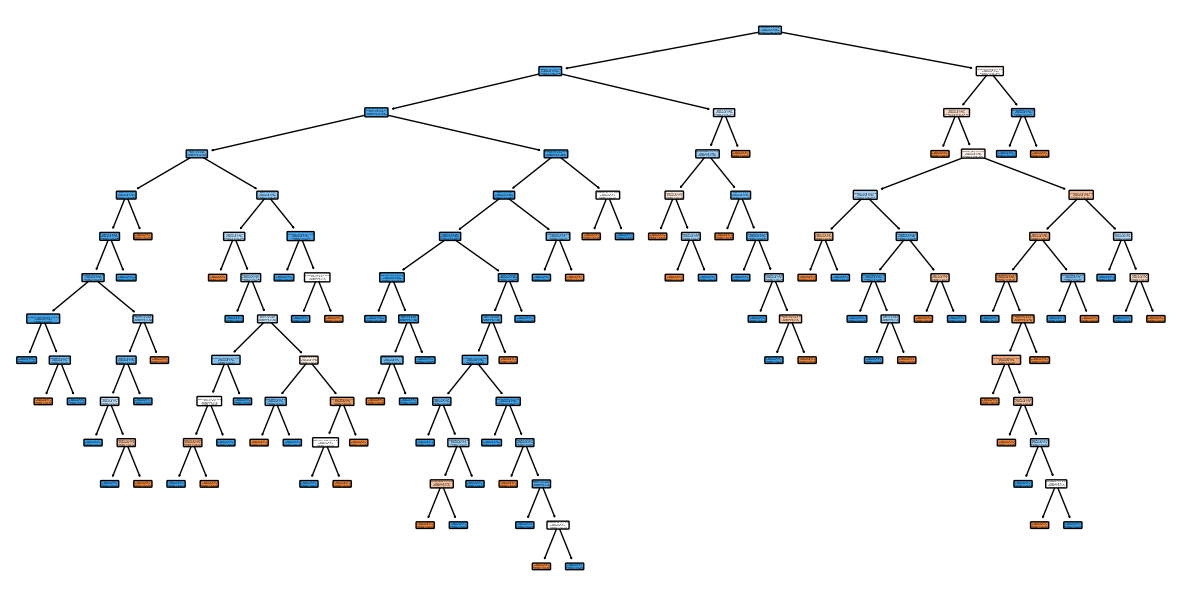

In [7]:
plt.figure(figsize=(15,7.5))
plot_tree(clf,
         filled = True,
         rounded = True,
          class_names = ['Pass','Fail'],
         feature_names = X_encoded.columns)
plt.show()

In [8]:
y_pred = clf.predict(X_test)

table = pd.crosstab(y_test, y_pred, rownames=['Truth'], colnames=['Predicted'])
table


Predicted,0,1
Truth,,
0,8,12
1,14,129


Now that we have a confusion matrix we can prune the tree, and compare the matrices

Same note as before, the Decision Tree is overfitting the data, we will set a value for opltimal alpha using cross validation.


<Axes: xlabel='alpha'>

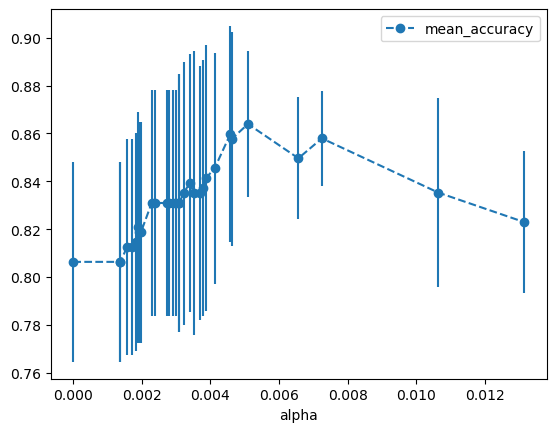

In [9]:
path = clf.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas
ccp_alphas = ccp_alphas[:-1]  

alpha_loop_values = []

for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state = 0, ccp_alpha = ccp_alpha)
    scores = cross_val_score(clf, X_train, y_train, cv= 10)
    alpha_loop_values.append([ccp_alpha, np.mean(scores),np.std(scores)])


alpha_results= pd.DataFrame(alpha_loop_values, columns= ['alpha','mean_accuracy','std'])

alpha_results.plot(x= 'alpha',
                  y = 'mean_accuracy',
                  yerr = 'std',
                  marker= 'o',
                  linestyle = '--')

In [10]:
optimal_alpha= alpha_results[(alpha_results['alpha']> 0.005) & (alpha_results['alpha']< 0.006)] ['alpha']
optimal_alpha = float(optimal_alpha)
optimal_alpha

C:\Users\Fatima zahra\AppData\Local\Temp\ipykernel_19512\2326669042.py:2: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  optimal_alpha = float(optimal_alpha)


0.005092761435034787

In [11]:
clf_pruned = DecisionTreeClassifier(random_state = 0, ccp_alpha= optimal_alpha)
clf_pruned = clf_pruned.fit(X_train, y_train)

In [12]:
y_pred = clf_pruned.predict(X_test)

table = pd.crosstab(y_test, y_pred, rownames=['Truth'], colnames=['Predicted'])
table


Predicted,0,1
Truth,,
0,4,16
1,7,136


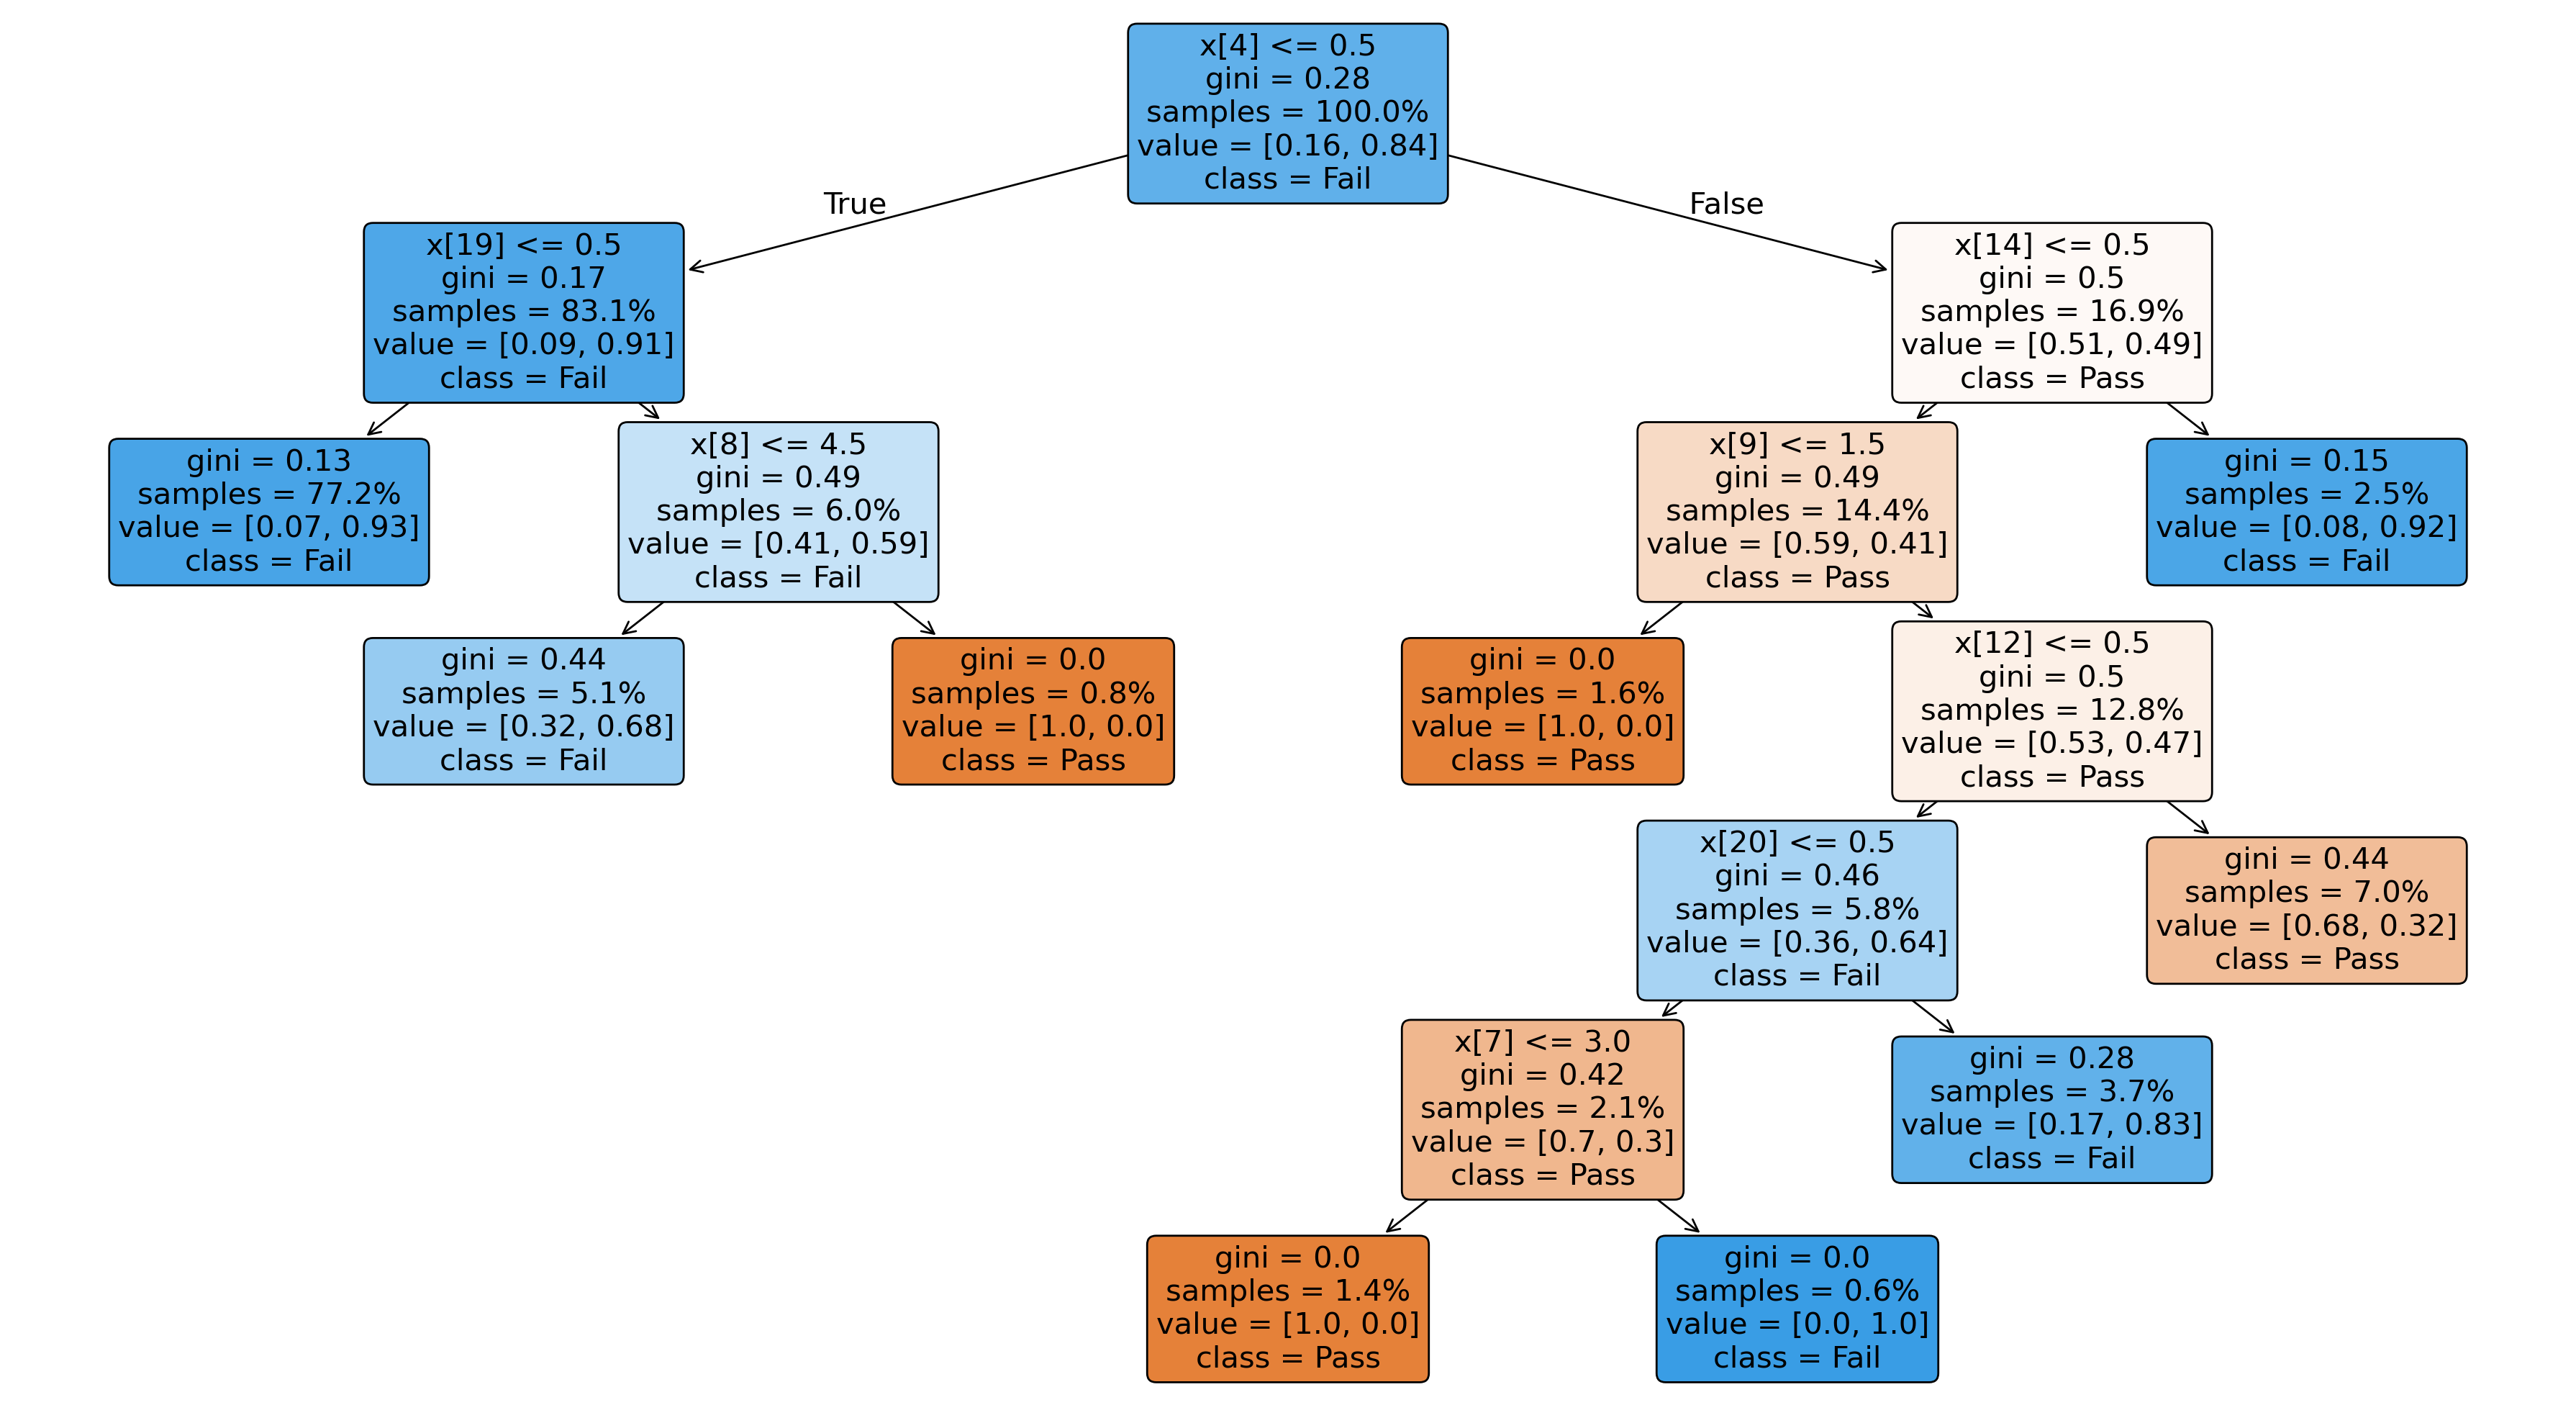

In [13]:

plt.figure(figsize=(18, 10), dpi=200)

plot_tree(
    clf_pruned,
    filled=True,
    rounded=True,
    class_names = ["Pass","Fail"],
    max_depth=10,            
    fontsize=15,             
    precision=2,            
    proportion=True         
)

plt.tight_layout()
plt.show()


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


<Figure size 800x600 with 0 Axes>

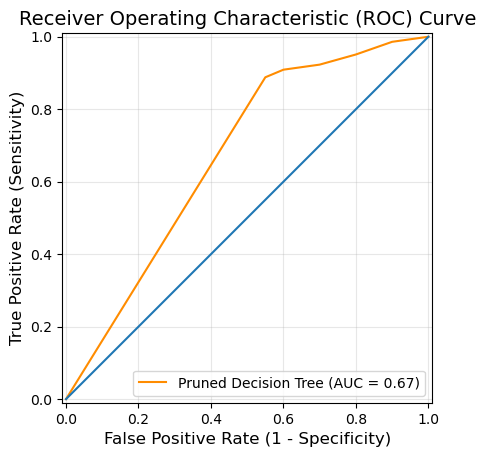

In [14]:
y_scores = clf_pruned.predict_proba(X_test)[:, 1]

plt.figure(figsize=(8, 6))
RocCurveDisplay.from_predictions(
    y_test, 
    y_scores, 
    name="Pruned Decision Tree", 
    color="darkorange"
)
plt.plot([0, 1], [0, 1])
plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=14)
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=12)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [15]:
roc_auc = roc_auc_score(y_test, y_scores)
print('ROC-AUC Decision Tree Score:', roc_auc)


ROC-AUC Decision Tree Score: 0.6706293706293707


Fair score, but we can do better. 

### Support Vector Machine

One of the most popular Classification Model is SVM, since it can map data into higher dimensions to solve complex, non-linear classification problems, Robust to Outliers and Excels in high-dimensional spaces

RBF assums that the data is scaled

In [16]:
#X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, random_state=0)


scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [17]:

clf_svm = SVC(random_state=0)
clf_svm.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [18]:

y_pred = clf_svm.predict(X_test_scaled)

table = pd.crosstab(y_test, y_pred, rownames=['Truth'], colnames=['Predicted'])
table


Predicted,0,1
Truth,,
0,1,19
1,4,139


At the first try, SVM didn't give good results. 
Using Cross Validation, we will try to optimize the regularization parameter, in order to have better accuracy on the test set.

ISLP mentions kernel="rbf" Instructs SVC to use the radial basis kernel function to map data into a higher-dimensional space. 

In [19]:
param_grid = {'C': [0.1, 1, 10, 20,100], 'gamma': [0.001, 0.01, 0.1], 'kernel': ['rbf']}
grid_search = GridSearchCV(SVC(), param_grid, cv=10)
grid_search.fit(X_train_scaled, y_train)
print(grid_search.best_params_)

{'C': 20, 'gamma': 0.01, 'kernel': 'rbf'}


In [20]:
optimized_svm = SVC(random_state=0, C=10, gamma= 0.01)
optimized_svm.fit(X_train_scaled, y_train)

,C,10
,kernel,'rbf'
,degree,3
,gamma,0.01
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [21]:

y_pred = optimized_svm.predict(X_test_scaled)

table = pd.crosstab(y_test, y_pred, rownames=['Truth'], colnames=['Predicted'])
table


Predicted,0,1
Truth,,
0,4,16
1,6,137


ROC AUC SVM Score:  0.8353146853146853


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\utils\_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


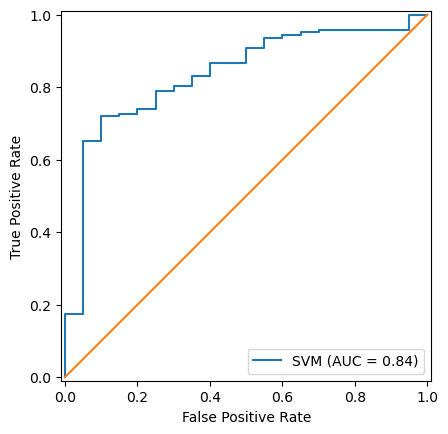

In [22]:
y_scores = optimized_svm.decision_function(X_test_scaled)

fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)
print('ROC AUC SVM Score: ',roc_auc)
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="SVM")
display.plot()
plt.plot([0, 1], [0, 1])
plt.legend(loc="lower right")
plt.show()


In the second try, when SVM is optimized, it gave slightly better results and that is shown in the ROC curve which represents a higher value of accuracy of the predictions. 

### Random Forest

In [23]:
rf_clf = RandomForestClassifier(n_estimators=100,random_state=0)
rf_clf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [24]:

y_pred = rf_clf.predict(X_test)

table = pd.crosstab(y_test, y_pred, rownames=['Truth'], colnames=['Predicted'])
table


Predicted,0,1
Truth,,
0,3,17
1,4,139


In [25]:

param_grid = {
    'n_estimators':[100, 200, 300],
    'max_depth': [10, 15, 20],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_clf,
    param_grid=param_grid,
    cv=10,
    scoring='accuracy',  
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
print('Best Hyperparameters:', grid_search.best_params_)


Best Hyperparameters: {'max_depth': 15, 'min_samples_leaf': 1, 'n_estimators': 100}


In [26]:
y_pred = best_rf.predict(X_test)

table = pd.crosstab(y_test, y_pred, rownames=['Truth'], colnames=['Predicted'])
table

Predicted,0,1
Truth,,
0,3,17
1,4,139


ROC AUC Random Forest Score: 0.8307692307692307


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\utils\_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


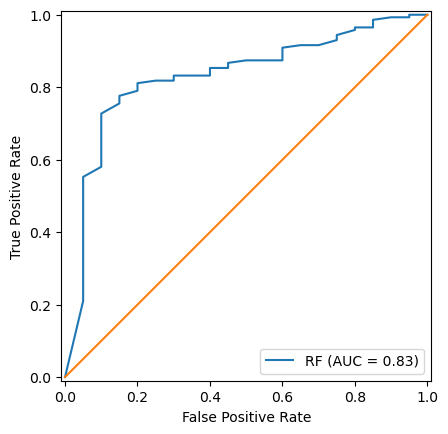

In [27]:


y_scores = best_rf.predict_proba(X_test)[:, 1]


fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)
print('ROC AUC Random Forest Score:', roc_auc)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='RF')
display.plot()
plt.plot([0, 1], [0, 1])
plt.legend(loc='lower right')
plt.show()


Both the SVM and Random Forest pushed performance deep into the 0.83+ ROC-AUC range, proving that student academic performance relies on complex feature interactions that single trees miss.

From the UCI, they mentionned that :"the target attribute G3 has a strong correlation with attributes G2 and G1. This occurs because G3 is the final year grade (issued at the 3rd period), while G1 and G2 correspond to the 1st and 2nd period grades". 

SO.. what if we run another SVM (since it was the best performance) with the dataframe including G1 and G2 and compare it to the past Evaluation test (confusion matrix and ROC)

In [28]:
df

,school,age,Medu,reason,traveltime,studytime,failures,nursery,higher,internet,famrel,freetime,Dalc,Walc,health,absences,G1,G2,G3,pass_fail
0,GP,18,4,course,2,2,0,yes,yes,no,4,3,1,1,3,4,0,11,11,1
1,GP,17,1,course,1,2,0,no,yes,yes,5,3,1,1,3,2,9,11,11,1
2,GP,15,1,other,1,2,0,yes,yes,yes,4,3,2,3,3,6,12,13,12,1
3,GP,15,4,home,1,3,0,yes,yes,yes,3,2,1,1,5,0,14,14,14,1
4,GP,16,3,home,1,2,0,yes,yes,no,4,3,1,2,5,0,11,13,13,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,19,2,course,1,3,1,no,yes,yes,5,4,1,2,5,4,10,11,10,1
645,MS,18,3,course,1,2,0,yes,yes,yes,4,3,1,1,1,4,15,15,16,1
646,MS,18,1,course,2,2,0,yes,yes,no,1,1,1,1,5,6,11,12,9,0
647,MS,17,3,course,2,1,0,no,yes,yes,2,4,3,4,2,6,10,10,10,1


In [29]:
X = df.drop(columns=["G3","pass_fail"])
y = df["pass_fail"]


In [30]:
X_enc = pd.get_dummies(X, columns=['school', 'reason', 'nursery', 'higher', 'internet'])
X_enc.head()

,age,Medu,traveltime,studytime,failures,famrel,freetime,Dalc,Walc,health,...,reason_course,reason_home,reason_other,reason_reputation,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes
0,18,4,2,2,0,4,3,1,1,3,...,True,False,False,False,False,True,False,True,True,False
1,17,1,1,2,0,5,3,1,1,3,...,True,False,False,False,True,False,False,True,False,True
2,15,1,1,2,0,4,3,2,3,3,...,False,False,True,False,False,True,False,True,False,True
3,15,4,1,3,0,3,2,1,1,5,...,False,True,False,False,False,True,False,True,False,True
4,16,3,1,2,0,4,3,1,2,5,...,False,True,False,False,False,True,False,True,True,False


### Support Vector Machine 2

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X_enc, y, random_state=0)

In [32]:

scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [34]:
clf_second_svm = SVC(random_state=0)
clf_second_svm.fit(X_train_scaled, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [35]:

y_pred = clf_second_svm.predict(X_test_scaled)

table = pd.crosstab(y_test, y_pred, rownames=['Truth'], colnames=['Predicted'])
table


Predicted,0,1
Truth,,
0,12,8
1,3,140


Beautiful!
Let's optimize it

In [36]:
param_grid = {'C': [0.1, 1, 10, 20,100], 'gamma': [0.001, 0.01, 0.1], 'kernel': ['rbf']}
grid_search = GridSearchCV(SVC(), param_grid, cv=10)
grid_search.fit(X_train_scaled, y_train)
print(grid_search.best_params_)

{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}


In [37]:
second_optimized_svm = SVC(random_state=0, C=10, gamma= 0.01)
second_optimized_svm.fit(X_train_scaled, y_train)

,C,10
,kernel,'rbf'
,degree,3
,gamma,0.01
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [38]:

y_pred = second_optimized_svm.predict(X_test_scaled)

table = pd.crosstab(y_test, y_pred, rownames=['Truth'], colnames=['Predicted'])
table


Predicted,0,1
Truth,,
0,15,5
1,4,139


ROC AUC Second SVM Score:  0.9573426573426573


C:\Users\Fatima zahra\anaconda3\Lib\site-packages\sklearn\utils\_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


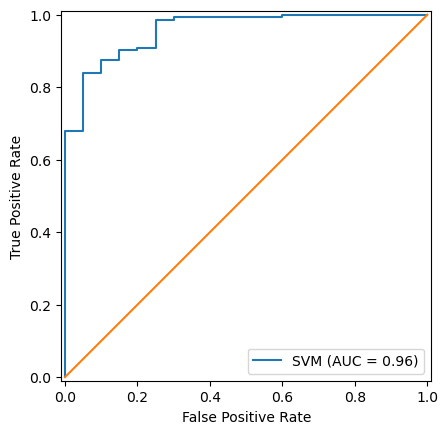

In [40]:
y_scores = second_optimized_svm.decision_function(X_test_scaled)

fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)
print('ROC AUC Second SVM Score: ',roc_auc)
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="SVM")
display.plot()
plt.plot([0, 1], [0, 1])
plt.legend(loc="lower right")
plt.show()


It is indeed perfect! 
G1 & G2 are obvious indicators to predict G3. 

Even when having the best results, this is absolutely **NOT** the best practice. since the Features Gs are strongly correlated, it is like introducing the answers at the test. 